# Reproducing CS-Flow on the Magnetic Tile Defects (MTD) dataset

**Paper:** *Fully Convolutional Cross-Scale-Flows for Image-based Defect Detection*, Rudolph, Wehrbein, Rosenhahn, Wandt (WACV 2022)
**Official code:** https://github.com/marco-rudolph/cs-flow
**Target result (paper Table 2):** image-level **AUROC = 99.3 %** on MTD


---
## Packages and GPU

Put this notebook in your project folder. Everything it creates (`MTD_raw/`, `data/`, `models/`, `viz/`, `results/`) goes next to it.

**Install order matters:** install PyTorch **first**, then the rest, otherwise `efficientnet-pytorch` can fail to build.
For the GPU you need the **CUDA build** of PyTorch: take the exact command from https://pytorch.org/get-started/locally/ .
Uncomment and run the next cell only if the check in 0.2 reports missing packages.

In [1]:
# Check packages and GPU
import importlib, sys

required = {'torch': 'torch', 'torchvision': 'torchvision', 'efficientnet_pytorch': 'efficientnet-pytorch',
            'sklearn': 'scikit-learn', 'scipy': 'scipy', 'matplotlib': 'matplotlib', 'tqdm': 'tqdm',
            'numpy': 'numpy', 'PIL': 'pillow'}
missing = []
for module, pip_name in required.items():
    try:
        m = importlib.import_module(module)
        print(f'  OK  {pip_name:22s} {getattr(m, "__version__", "")}')
    except ImportError:
        missing.append(pip_name)
        print(f'  --  {pip_name:22s} MISSING')
if missing:
    raise ImportError('Missing packages: ' + ', '.join(missing) + '  -> install them with cell 0.1, then restart the kernel.')

import torch
print('\nPython :', sys.version.split()[0])
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f'GPU    : {props.name}, {props.total_memory / 1024**3:.1f} GB  -> training runs on the GPU')
else:
    print('GPU    : NOT FOUND -> everything runs on the CPU (the quick test works, full training would take many hours).')
    print('         If you have an NVIDIA GPU, install the CUDA build of PyTorch (cell 0.1) and restart the kernel.')

  OK  torch                  2.11.0+cu128
  OK  torchvision            0.26.0+cu128
  OK  efficientnet-pytorch   0.7.1
  OK  scikit-learn           1.7.1
  OK  scipy                  1.18.1
  OK  matplotlib             3.9.3
  OK  tqdm                   4.68.4
  OK  numpy                  2.5.4
  OK  pillow                 12.3.0

Python : 3.12.8
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU, 8.0 GB  -> training runs on the GPU


In [3]:
%pip install efficientnet-pytorch

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for efficientnet-pytorch: filename=efficientnet_pytorch-0.7.1-py3-none-any.whl size=16520 sha256=61986cd7274a5329606d636d8cf2675c0da16df053eeb120afbc022fc56423b4
  Stored in directory: c:\users\user\appdata\local\pip\cache\wheels\9c\3f\43\e6271c7026fe08c185da2be23c98c8e87477d3db63f41f32ad
Successfully built efficientnet-pytorch
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## 1. Imports
All imports of all repository files, in one place.

In [2]:
import os, re, json, time, shutil, random, warnings, subprocess, urllib.request, zipfile
from pathlib import Path
from math import exp
from copy import deepcopy
from os.path import join
from types import SimpleNamespace

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
from torch.utils.data import Dataset
from torchvision import datasets, transforms
from torchvision.datasets import ImageFolder
from efficientnet_pytorch import EfficientNet
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tqdm import tqdm
import matplotlib.pyplot as plt
import PIL.Image
from IPython.display import Image, display, Markdown

PROJECT_DIR = Path.cwd()   # all data, models and figures are stored here
os.chdir(PROJECT_DIR)      # the repository code uses paths relative to this folder
print('Project folder:', PROJECT_DIR)

Project folder: D:\learning 2\university\ENTC\5th sem\Image Processing and Machine Vision\Project\New Implementation\Notebook Implementation


---
## 2. Configuration (`config.py`)


In [4]:
# config.py  -  all settings for CS-Flow (data, model, training) in one object `c`
c = SimpleNamespace()

# Device settings
c.device = 'cuda' if torch.cuda.is_available() else 'cpu' 

# Data settings
c.dataset_path = 'data/mtd_data'  # parent directory of datasets
c.class_name = 'mtd'  # dataset subdirectory
c.modelname = 'mtd_seed0'  # export evaluations/logs with this name
c.pre_extracted = True  # were feature preextracted with extract_features?

c.img_size = (384, 384)  # image size of highest scale

# Transformation settings (ImageNet normalisation - EfficientNet was trained on ImageNet)
c.norm_mean, c.norm_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Network hyperparameters
c.n_scales = 3  # number of scales at which features are extracted
c.clamp = 3  # clamping parameter (alpha in paper Eq. 4)
c.max_grad_norm = 1e0  # clamp gradients to this norm
c.n_coupling_blocks = 4  # higher = more flexible = more unstable
c.fc_internal = 1024  # * 4 # number of neurons in hidden layers of s-t-networks
c.lr_init = 2e-4  # inital learning rate
c.use_gamma = True  # learnable gamma scaling inside the subnetworks
c.extractor = "effnetB5"  # feature dataset name

# Dataloader parameters
c.batch_size = 16

# Training length: total epochs = meta_epochs * sub_epochs; the test AUROC is printed after
# every <sub_epochs> epochs.  MTD: 4 x 15 = 60 epochs.  MVTec AD: 4 x 60 = 240 epochs.
c.meta_epochs = 4  # total epochs = meta_epochs * sub_epochs
c.sub_epochs = 15  # evaluate after this number of epochs

# Output settings
c.verbose = True
c.hide_tqdm_bar = True
c.save_model = True  # save the trained model

# Values derived from the settings above
def update_derived():
    assert c.img_size[0] % 128 == 0 and c.img_size[1] % 128 == 0, "image width/height should be a multiple of 128"
    c.img_dims = [3] + list(c.img_size)
    c.n_feat = {"effnetB5": 304}[c.extractor]  # dependend from feature extractor
    c.map_size = (c.img_size[0] // 32, c.img_size[1] // 32)  # spatial size of the largest feature map
    c.kernel_sizes = [3] * (c.n_coupling_blocks - 1) + [5]  # last coupling block uses 5x5 kernels


def set_config(**settings):
    """Change settings, e.g. set_config(class_name='mtd', sub_epochs=15). Always use this, not c.x = ..."""
    for name, value in settings.items():
        if not hasattr(c, name):
            raise KeyError(f'unknown setting: {name}')
        setattr(c, name, value)
    update_derived()
    print('config:', ', '.join(f'{k}={v!r}' for k, v in settings.items()))


def show_config():
    keys = ['device', 'dataset_path', 'class_name', 'modelname', 'img_size', 'map_size', 'batch_size', 'meta_epochs', 'sub_epochs']
    print(' | '.join(f'{k}={getattr(c, k)!r}' for k in keys) + f'  -> {c.meta_epochs * c.sub_epochs} epochs')


update_derived()
show_config()

device='cuda' | dataset_path='data/mtd_data' | class_name='mtd' | modelname='mtd_seed0' | img_size=(384, 384) | map_size=(12, 12) | batch_size=16 | meta_epochs=4 | sub_epochs=15  -> 60 epochs


---
## 3. The repository's code (one cell per file)

```

### 3.1 `utils.py`


In [5]:
# utils.py  -  loss, datasets and helpers
import os
import torch
from torchvision import datasets, transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset
import numpy as np

import gc

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Tensor helpers
def t2np(tensor):
    '''pytorch tensor -> numpy array'''
    return tensor.cpu().data.numpy() if tensor is not None else None


def flat(tensor):
    return tensor.reshape(tensor.shape[0], -1)


def concat_maps(maps):
    # flattens the 3 output maps (one per scale) and joins them into one vector per sample
    flat_maps = list()
    for m in maps:
        flat_maps.append(flat(m))
    return torch.cat(flat_maps, dim=1)[..., None]

# Loss: negative log-likelihood of a standard normal latent space, minus the
# log-Jacobian determinant, normalised by the number of dimensions (paper Eq. 6)
def get_loss(z, jac):
    z = torch.cat([z[i].reshape(z[i].shape[0], -1) for i in range(len(z))], dim=1)
    jac = sum(jac)
    return torch.mean(0.5 * torch.sum(z ** 2, dim=(1,)) - jac) / z.shape[1]


def cat_maps(z):
    return torch.cat([z[i].reshape(z[i].shape[0], -1) for i in range(len(z))], dim=1)

# Dataset loading
def load_datasets(dataset_path, class_name):
    '''
    Expected folder/file format to find anomalies of class <class_name> from dataset location <dataset_path>:

    train data:

            dataset_path/class_name/train/good/any_filename.png
            dataset_path/class_name/train/good/another_filename.tif
            dataset_path/class_name/train/good/xyz.png
            [...]

    test data:

        'normal data' = non-anomalies

            dataset_path/class_name/test/good/name_the_file_as_you_like_as_long_as_there_is_an_image_extension.webp
            dataset_path/class_name/test/good/did_you_know_the_image_extension_webp?.png
            dataset_path/class_name/test/good/did_you_know_that_filenames_may_contain_question_marks????.png
            dataset_path/class_name/test/good/dont_know_how_it_is_with_windows.png
            dataset_path/class_name/test/good/just_dont_use_windows_for_this.png
            [...]

        anomalies - assume there are anomaly classes 'crack' and 'curved'

            dataset_path/class_name/test/crack/dat_crack_damn.png
            dataset_path/class_name/test/crack/let_it_crack.png
            dataset_path/class_name/test/crack/writing_docs_is_fun.png
            [...]

            dataset_path/class_name/test/curved/wont_make_a_difference_if_you_put_all_anomalies_in_one_class.png
            dataset_path/class_name/test/curved/but_this_code_is_practicable_for_the_mvtec_dataset.png
            [...]
    '''

    def target_transform(target):
        return class_perm[target]

    if c.pre_extracted:
        trainset = FeatureDataset(train=True)
        testset = FeatureDataset(train=False)
    else:
        data_dir_train = os.path.join(dataset_path, class_name, 'train')
        data_dir_test = os.path.join(dataset_path, class_name, 'test')

        classes = os.listdir(data_dir_test)
        if 'good' not in classes:
            raise FileNotFoundError('There should exist a subdirectory "good". Read the doc of this function for further information.')
        classes.sort()
        class_perm = list()
        class_idx = 1
        for cl in classes:
            if cl == 'good':
                class_perm.append(0)
            else:
                class_perm.append(class_idx)
                class_idx += 1

        # resize -> tensor -> ImageNet normalisation (grayscale MTD images are converted to RGB by ImageFolder)
        tfs = [transforms.Resize(c.img_size), transforms.ToTensor(), transforms.Normalize(c.norm_mean, c.norm_std)]
        transform_train = transforms.Compose(tfs)

        trainset = ImageFolder(data_dir_train, transform=transform_train)
        testset = ImageFolder(data_dir_test, transform=transform_train, target_transform=target_transform)
    return trainset, testset


class FeatureDataset(Dataset):
    '''Serves the cached features written by extract_features.py:
    data/features/<class_name>/<class_name>_scale_<s>_<train|test>.npy'''

    def __init__(self, root=None, n_scales=None, train=False):
        if root is None:
            root = "data/features/" + c.class_name + '/'
        if n_scales is None:
            n_scales = c.n_scales

        super(FeatureDataset, self).__init__()
        self.data = list()
        self.n_scales = n_scales
        self.train = train
        suffix = 'train' if train else 'test'

        for s in range(c.n_scales):
            self.data.append(np.load(root + c.class_name + '_scale_' + str(s) + '_' + suffix + '.npy'))

        self.labels = np.load(os.path.join(root, c.class_name + '_labels.npy')) if not train else np.zeros(
            [len(self.data[0])])
        self.paths = np.load(os.path.join(root, c.class_name + '_image_paths.npy'))
        # [NOTEBOOK FIX] was: img_path.split('/')[-2]  (breaks on Windows paths)
        self.class_names = [os.path.basename(os.path.dirname(str(img_path))) for img_path in self.paths]

    def __len__(self):
        return len(self.data[0])

    def __getitem__(self, index):
        out = list()
        for d in self.data:
            sample = d[index]
            sample = torch.FloatTensor(sample)
            out.append(sample)
        return out, self.labels[index]


def make_dataloaders(trainset, testset):
    trainloader = torch.utils.data.DataLoader(trainset, pin_memory=True, batch_size=c.batch_size, shuffle=True,
                                              drop_last=False)
    testloader = torch.utils.data.DataLoader(testset, pin_memory=True, batch_size=c.batch_size, shuffle=False,
                                             drop_last=False)
    return trainloader, testloader


# Move a batch to the GPU/CPU (features come as a list of 3 tensors, one per scale)
def preprocess_batch(data):
    '''move data to device and reshape image'''
    if c.pre_extracted:
        inputs, labels = data
        for i in range(len(inputs)):
            inputs[i] = inputs[i].to(c.device)
        labels = labels.to(c.device)
    else:
        inputs, labels = data
        inputs, labels = inputs.to(c.device), labels.to(c.device)
        inputs = inputs.view(-1, *inputs.shape[-3:])
    return inputs, labels


# Keeps track of the latest and best test score.
class Score_Observer:
    '''Keeps an eye on the current and highest score so far'''

    def __init__(self, name):
        self.name = name
        self.max_epoch = 0
        self.max_score = None
        self.min_loss_epoch = 0
        self.min_loss_score = 0
        self.min_loss = None
        self.last = None

    def update(self, score, epoch, print_score=False):
        self.last = score
        if self.max_score == None or score > self.max_score:
            self.max_score = score
            self.max_epoch = epoch
        if print_score:
            self.print_score()

    def print_score(self):
        print('{:s}: \t last: {:.4f} \t max: {:.4f} \t epoch_max: {:d} \t epoch_loss: {:d}'.format(self.name, self.last,
                                                                                                   self.max_score,
                                                                                                   self.max_epoch,
                                                                                                   self.min_loss_epoch))

### 3.2 `freia_funcs.py`
* `CrossConvolutions`: the cross-scale subnetwork (paper **Fig. 4**).
* `parallel_glow_coupling_layer`: affine coupling block (paper **Eq. 3**) with the soft clamp (paper **Eq. 4**).
* The rest is generic graph code from the FrEIA framework.

In [6]:
# freia_funcs.py  -  normalizing-flow building blocks (from the FrEIA framework)
'''This Code is based on the FrEIA Framework, source: https://github.com/VLL-HD/FrEIA
It is a assembly of the necessary modules/functions from FrEIA that are needed for our purposes.'''
import torch
import torch.nn as nn
from torch.autograd import Variable
from math import exp
import numpy as np

VERBOSE = False


# Placeholder that only carries the input shape of an InputNode
class dummy_data:
    def __init__(self, *dims):
        self.dims = dims

    @property
    def shape(self):
        return self.dims

# Cross-scale subnetwork (paper Fig. 4)
class CrossConvolutions(nn.Module):
    '''ResNet transformation, not itself reversible, just used below'''

    def __init__(self, in_channels, channels, channels_hidden=512,
                 stride=None, kernel_size=3, last_kernel_size=1, leaky_slope=0.1,
                 batch_norm=False, block_no=0):
        super(CrossConvolutions, self).__init__()
        if stride:
            warnings.warn("Stride doesn't do anything, the argument should be "
                          "removed", DeprecationWarning)
        if not channels_hidden:
            channels_hidden = channels

        pad = kernel_size // 2
        self.leaky_slope = leaky_slope
        pad_mode = 'zeros'

        self.gamma0 = nn.Parameter(torch.zeros(1))
        self.gamma1 = nn.Parameter(torch.zeros(1))
        self.gamma2 = nn.Parameter(torch.zeros(1))

        self.conv_scale0_0 = nn.Conv2d(in_channels, channels_hidden,
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode)

        self.conv_scale1_0 = nn.Conv2d(in_channels, channels_hidden,
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode)
        self.conv_scale2_0 = nn.Conv2d(in_channels, channels_hidden,
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode)
        self.conv_scale0_1 = nn.Conv2d(channels_hidden * 1, channels,  #
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode, dilation=1)
        self.conv_scale1_1 = nn.Conv2d(channels_hidden * 1, channels,  #
                                       kernel_size=kernel_size, padding=pad * 1,
                                       bias=not batch_norm, padding_mode=pad_mode, dilation=1)
        self.conv_scale2_1 = nn.Conv2d(channels_hidden * 1, channels,  #
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode)

        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)

        self.up_conv10 = nn.Conv2d(channels_hidden, channels,
                                   kernel_size=kernel_size, padding=pad, bias=True, padding_mode=pad_mode)

        self.up_conv21 = nn.Conv2d(channels_hidden, channels,
                                   kernel_size=kernel_size, padding=pad, bias=True, padding_mode=pad_mode)

        self.down_conv01 = nn.Conv2d(channels_hidden, channels,
                                     kernel_size=kernel_size, padding=pad,
                                     bias=not batch_norm, stride=2, padding_mode=pad_mode, dilation=1)

        self.down_conv12 = nn.Conv2d(channels_hidden, channels,
                                     kernel_size=kernel_size, padding=pad,
                                     bias=not batch_norm, stride=2, padding_mode=pad_mode, dilation=1)

        self.lr = nn.LeakyReLU(self.leaky_slope)

    def forward(self, x0, x1, x2):
        out0 = self.conv_scale0_0(x0)
        out1 = self.conv_scale1_0(x1)
        out2 = self.conv_scale2_0(x2)

        y0 = self.lr(out0)
        y1 = self.lr(out1)
        y2 = self.lr(out2)

        out0 = self.conv_scale0_1(y0)
        out1 = self.conv_scale1_1(y1)
        out2 = self.conv_scale2_1(y2)

        y1_up = self.up_conv10(self.upsample(y1))
        y2_up = self.up_conv21(self.upsample(y2))

        y0_down = self.down_conv01(y0)
        y1_down = self.down_conv12(y1)

        out0 = out0 + y1_up
        out1 = out1 + y0_down + y2_up
        out2 = out2 + y1_down

        if c.use_gamma:
            out0 = out0 * self.gamma0
            out1 = out1 * self.gamma1
            out2 = out2 * self.gamma2
        return out0, out1, out2


# Fixed random channel permutation (one per scale), applied before each coupling block
class ParallelPermute(nn.Module):
    '''permutes input vector in a random but fixed way'''

    def __init__(self, dims_in, seed):
        super(ParallelPermute, self).__init__()
        # print('dims in', dims_in)
        # exit()
        self.n_inputs = len(dims_in)
        self.in_channels = [dims_in[i][0] for i in range(self.n_inputs)]

        np.random.seed(seed)
        perm, perm_inv = self.get_random_perm(0)
        self.perm = [perm]
        self.perm_inv = [perm_inv]

        for i in range(1, self.n_inputs):
            perm, perm_inv = self.get_random_perm(i)
            self.perm.append(perm)
            self.perm_inv.append(perm_inv)

    def get_random_perm(self, i):
        perm = np.random.permutation(self.in_channels[i])
        perm_inv = np.zeros_like(perm)
        for i, p in enumerate(perm):
            perm_inv[p] = i

        perm = torch.LongTensor(perm)
        perm_inv = torch.LongTensor(perm_inv)
        return perm, perm_inv

    def forward(self, x, rev=False):
        if not rev:
            return [x[i][:, self.perm[i]] for i in range(self.n_inputs)]
        else:
            return [x[i][:, self.perm_inv[i]] for i in range(self.n_inputs)]

    def jacobian(self, x, rev=False):
        # TODO: use batch size, set as nn.Parameter so cuda() works
        return [0.] * self.n_inputs

    def output_dims(self, input_dims):
        return input_dims


# Affine coupling block (paper Eq. 3): split channels in two halves, transform one
# half with scale e(s) and shift t predicted from the other half, then swap roles.
# The log-Jacobian of each scale is stored in self.last_jac.
class parallel_glow_coupling_layer(nn.Module):
    def __init__(self, dims_in, F_class=CrossConvolutions, F_args={},
                 clamp=5.):
        super(parallel_glow_coupling_layer, self).__init__()
        channels = dims_in[0][0]
        self.ndims = len(dims_in[0])

        self.split_len1 = channels // 2
        self.split_len2 = channels - channels // 2

        self.clamp = clamp

        self.max_s = exp(clamp)
        self.min_s = exp(-clamp)

        self.s1 = F_class(self.split_len1, self.split_len2 * 2, **F_args)
        self.s2 = F_class(self.split_len2, self.split_len1 * 2, **F_args)

    def e(self, s):
        if self.clamp > 0:
            return torch.exp(self.log_e(s))
        else:
            return torch.exp(s)

    def log_e(self, s):
        if self.clamp > 0:
            return self.clamp * 0.636 * torch.atan(s / self.clamp)
        else:
            return s

    def forward(self, x, rev=False):
        x01, x02 = (x[0].narrow(1, 0, self.split_len1),
                    x[0].narrow(1, self.split_len1, self.split_len2))
        x11, x12 = (x[1].narrow(1, 0, self.split_len1),
                    x[1].narrow(1, self.split_len1, self.split_len2))
        x21, x22 = (x[2].narrow(1, 0, self.split_len1),
                    x[2].narrow(1, self.split_len1, self.split_len2))

        if not rev:
            r02, r12, r22 = self.s2(x02, x12, x22)

            s02, t02 = r02[:, :self.split_len1], r02[:, self.split_len1:]
            s12, t12 = r12[:, :self.split_len1], r12[:, self.split_len1:]
            s22, t22 = r22[:, :self.split_len1], r22[:, self.split_len1:]

            y01 = self.e(s02) * x01 + t02
            y11 = self.e(s12) * x11 + t12
            y21 = self.e(s22) * x21 + t22

            r01, r11, r21 = self.s1(y01, y11, y21)

            s01, t01 = r01[:, :self.split_len2], r01[:, self.split_len2:]
            s11, t11 = r11[:, :self.split_len2], r11[:, self.split_len2:]
            s21, t21 = r21[:, :self.split_len2], r21[:, self.split_len2:]
            y02 = self.e(s01) * x02 + t01
            y12 = self.e(s11) * x12 + t11
            y22 = self.e(s21) * x22 + t21

        else:  # names of x and y are swapped!
            r01, r11, r21 = self.s1(x01, x11, x21)

            s01, t01 = r01[:, :self.split_len2], r01[:, self.split_len2:]
            s11, t11 = r11[:, :self.split_len2], r11[:, self.split_len2:]
            s21, t21 = r21[:, :self.split_len2], r21[:, self.split_len2:]

            y02 = (x02 - t01) / self.e(s01)
            y12 = (x12 - t11) / self.e(s11)
            y22 = (x22 - t21) / self.e(s21)

            r02, r12, r22 = self.s2(y02, y12, y22)

            s02, t02 = r02[:, :self.split_len2], r01[:, self.split_len2:]
            s12, t12 = r12[:, :self.split_len2], r11[:, self.split_len2:]
            s22, t22 = r22[:, :self.split_len2], r21[:, self.split_len2:]

            y01 = (x01 - t02) / self.e(s02)
            y11 = (x11 - t12) / self.e(s12)
            y21 = (x21 - t22) / self.e(s22)

        y0 = torch.cat((y01, y02), 1)
        y1 = torch.cat((y11, y12), 1)
        y2 = torch.cat((y21, y22), 1)

        y0 = torch.clamp(y0, -1e6, 1e6)
        y1 = torch.clamp(y1, -1e6, 1e6)
        y2 = torch.clamp(y2, -1e6, 1e6)

        jac0 = torch.sum(self.log_e(s01), dim=(1, 2, 3)) + torch.sum(self.log_e(s02), dim=(1, 2, 3))
        jac1 = torch.sum(self.log_e(s11), dim=(1, 2, 3)) + torch.sum(self.log_e(s12), dim=(1, 2, 3))
        jac2 = torch.sum(self.log_e(s21), dim=(1, 2, 3)) + torch.sum(self.log_e(s22), dim=(1, 2, 3))
        self.last_jac = [jac0, jac1, jac2]

        return [y0, y1, y2]

    def jacobian(self, x, rev=False):
        return self.last_jac

    def output_dims(self, input_dims):
        return input_dims


# Graph machinery (generic FrEIA code): nodes, inputs, outputs and the network
class Node:
    '''The Node class represents one transformation in the graph, with an
    arbitrary number of in- and outputs.'''

    def __init__(self, inputs, module_type, module_args, name=None):
        self.inputs = inputs
        self.outputs = []
        self.module_type = module_type
        self.module_args = module_args

        self.input_dims, self.module = None, None
        self.computed = None
        self.computed_rev = None
        self.id = None

        if name:
            self.name = name
        else:
            self.name = hex(id(self))[-6:]
        for i in range(255):
            exec('self.out{0} = (self, {0})'.format(i))

    def build_modules(self, verbose=VERBOSE):
        ''' Returns a list with the dimension of each output of this node,
        recursively calling build_modules of the nodes connected to the input.
        Use this information to initialize the pytorch nn.Module of this node.
        '''

        if not self.input_dims:  # Only do it if this hasn't been computed yet
            self.input_dims = [n.build_modules(verbose=verbose)[c]
                               for n, c in self.inputs]
            try:
                self.module = self.module_type(self.input_dims,
                                               **self.module_args)
            except Exception as e:
                print('Error in node %s' % (self.name))
                raise e

            if verbose:
                print("Node %s has following input dimensions:" % (self.name))
                for d, (n, c) in zip(self.input_dims, self.inputs):
                    print("\t Output #%i of node %s:" % (c, n.name), d)
                print()

            self.output_dims = self.module.output_dims(self.input_dims)
            self.n_outputs = len(self.output_dims)

        return self.output_dims

    def run_forward(self, op_list):
        '''Determine the order of operations needed to reach this node. Calls
        run_forward of parent nodes recursively. Each operation is appended to
        the global list op_list, in the form (node ID, input variable IDs,
        output variable IDs)'''

        if not self.computed:

            # Compute all nodes which provide inputs, filter out the
            # channels you need
            self.input_vars = []
            for i, (n, c) in enumerate(self.inputs):
                self.input_vars.append(n.run_forward(op_list)[c])
                # Register youself as an output in the input node
                n.outputs.append((self, i))

            # All outputs could now be computed
            self.computed = [(self.id, i) for i in range(self.n_outputs)]
            op_list.append((self.id, self.input_vars, self.computed))

        # Return the variables you have computed (this happens mulitple times
        # without recomputing if called repeatedly)
        return self.computed

    def run_backward(self, op_list):
        '''See run_forward, this is the same, only for the reverse computation.
        Need to call run_forward first, otherwise this function will not
        work'''

        assert len(self.outputs) > 0, "Call run_forward first"
        if not self.computed_rev:

            # These are the input variables that must be computed first
            output_vars = [(self.id, i) for i in range(self.n_outputs)]

            # Recursively compute these
            for n, c in self.outputs:
                n.run_backward(op_list)

            # The variables that this node computes are the input variables
            # from the forward pass
            self.computed_rev = self.input_vars
            op_list.append((self.id, output_vars, self.computed_rev))

        return self.computed_rev


class InputNode(Node):
    '''Special type of node that represents the input data of the whole net (or
    ouput when running reverse)'''

    def __init__(self, *dims, name='node'):
        self.name = name
        self.data = dummy_data(*dims)
        self.outputs = []
        self.module = None
        self.computed_rev = None
        self.n_outputs = 1
        self.input_vars = []
        self.out0 = (self, 0)

    def build_modules(self, verbose=VERBOSE):
        return [self.data.shape]

    def run_forward(self, op_list):
        return [(self.id, 0)]


class OutputNode(Node):
    '''Special type of node that represents the output of the whole net (of the
    input when running in reverse)'''

    class dummy(nn.Module):

        def __init__(self, *args):
            super(OutputNode.dummy, self).__init__()

        def __call__(*args):
            return args

        def output_dims(*args):
            return args

    def __init__(self, inputs, name='node'):
        self.module_type, self.module_args = self.dummy, {}
        self.output_dims = []
        self.inputs = inputs
        self.input_dims, self.module = None, None
        self.computed = None
        self.id = None
        self.name = name

        for c, inp in enumerate(self.inputs):
            inp[0].outputs.append((self, c))

    def run_backward(self, op_list):
        return [(self.id, 0)]


# The complete invertible network. forward() maps features -> latent z;
# jacobian() returns the summed log-determinants (one per scale, n_jac=3).
class ReversibleGraphNet(nn.Module):
    '''This class represents the invertible net itself. It is a subclass of
    torch.nn.Module and supports the same methods. The forward method has an
    additional option 'rev', whith which the net can be computed in reverse.'''

    def __init__(self, node_list, ind_in=None, ind_out=None, verbose=False, n_jac=1):
        '''node_list should be a list of all nodes involved, and ind_in,
        ind_out are the indexes of the special nodes InputNode and OutputNode
        in this list.'''
        super(ReversibleGraphNet, self).__init__()

        # Gather lists of input and output nodes
        if ind_in is not None:
            if isinstance(ind_in, int):
                self.ind_in = list([ind_in])
            else:
                self.ind_in = ind_in
        else:
            self.ind_in = [i for i in range(len(node_list))
                           if isinstance(node_list[i], InputNode)]
            assert len(self.ind_in) > 0, "No input nodes specified."
        if ind_out is not None:
            if isinstance(ind_out, int):
                self.ind_out = list([ind_out])
            else:
                self.ind_out = ind_out
        else:
            self.ind_out = [i for i in range(len(node_list))
                            if isinstance(node_list[i], OutputNode)]
            assert len(self.ind_out) > 0, "No output nodes specified."

        self.return_vars = []
        self.input_vars = []

        # Assign each node a unique ID
        self.node_list = node_list
        for i, n in enumerate(node_list):
            n.id = i

        # Recursively build the nodes nn.Modules and determine order of
        # operations
        ops = []
        for i in self.ind_out:
            node_list[i].build_modules(verbose=verbose)
            node_list[i].run_forward(ops)

        # create list of Pytorch variables that are used
        variables = set()
        for o in ops:
            variables = variables.union(set(o[1] + o[2]))
        self.variables_ind = list(variables)

        self.indexed_ops = self.ops_to_indexed(ops)

        self.module_list = nn.ModuleList([n.module for n in node_list])
        self.variable_list = [Variable(requires_grad=True) for v in variables]

        # Find out the order of operations for reverse calculations
        ops_rev = []
        for i in self.ind_in:
            node_list[i].run_backward(ops_rev)
        self.indexed_ops_rev = self.ops_to_indexed(ops_rev)
        self.n_jac = n_jac

    def ops_to_indexed(self, ops):
        '''Helper function to translate the list of variables (origin ID, channel),
        to variable IDs.'''
        result = []

        for o in ops:
            try:
                vars_in = [self.variables_ind.index(v) for v in o[1]]
            except ValueError:
                vars_in = -1

            vars_out = [self.variables_ind.index(v) for v in o[2]]

            # Collect input/output nodes in separate lists, but don't add to
            # indexed ops
            if o[0] in self.ind_out:
                self.return_vars.append(self.variables_ind.index(o[1][0]))
                continue
            if o[0] in self.ind_in:
                self.input_vars.append(self.variables_ind.index(o[1][0]))
                continue

            result.append((o[0], vars_in, vars_out))

        # Sort input/output variables so they correspond to initial node list
        # order
        self.return_vars.sort(key=lambda i: self.variables_ind[i][0])
        self.input_vars.sort(key=lambda i: self.variables_ind[i][0])

        return result

    def forward(self, x, rev=False):
        '''Forward or backward computation of the whole net.'''
        if rev:
            use_list = self.indexed_ops_rev
            input_vars, output_vars = self.return_vars, self.input_vars
        else:
            use_list = self.indexed_ops
            input_vars, output_vars = self.input_vars, self.return_vars

        if isinstance(x, (list, tuple)):
            assert len(x) == len(input_vars), (
                f"Got list of {len(x)} input tensors for "
                f"{'inverse' if rev else 'forward'} pass, but expected "
                f"{len(input_vars)}."
            )
            for i in range(len(input_vars)):
                self.variable_list[input_vars[i]] = x[i]
        else:
            assert len(input_vars) == 1, (f"Got single input tensor for "
                                          f"{'inverse' if rev else 'forward'} "
                                          f"pass, but expected list of "
                                          f"{len(input_vars)}.")
            self.variable_list[input_vars[0]] = x

        for o in use_list:
            try:
                results = self.module_list[o[0]]([self.variable_list[i]
                                                  for i in o[1]], rev=rev)
            except TypeError:
                raise RuntimeError("Are you sure all used Nodes are in the "
                                   "Node list?")
            for i, r in zip(o[2], results):
                self.variable_list[i] = r
            # self.variable_list[o[2][0]] = self.variable_list[o[1][0]]

        out = [self.variable_list[output_vars[i]]
               for i in range(len(output_vars))]
        if len(out) == 1:
            return out[0]
        else:
            return out

    def jacobian(self, x=None, rev=False, run_forward=True):
        '''Compute the jacobian determinant of the whole net.'''
        jacobian = [0.] * self.n_jac

        if rev:
            use_list = self.indexed_ops_rev
        else:
            use_list = self.indexed_ops

        if run_forward:
            if x is None:
                raise RuntimeError("You need to provide an input if you want "
                                   "to run a forward pass")
            self.forward(x, rev=rev)

        for o in use_list:
            try:
                node_jac = self.module_list[o[0]].jacobian(
                    [self.variable_list[i] for i in o[1]], rev=rev
                )
                node_jac = [node_jac] if not isinstance(node_jac, list) else node_jac
                for i_j, jac in enumerate(node_jac):
                    jacobian[i_j] += jac

            except TypeError:
                raise RuntimeError("Are you sure all used Nodes are in the "
                                   "Node list?")

        return jacobian

### 3.3 `model.py`
* `get_cs_flow_model`: 3 inputs (one per scale) → 4 × [permutation → coupling block] → 3 latent outputs.
* `FeatureExtractor`: frozen ImageNet EfficientNet-B5, block 36, at full, ½ and ¼ resolution (paper **Fig. 1**).


In [7]:
# model.py  -  CS-Flow network and the feature extractor
import numpy as np
import os
import torch
import torch.nn.functional as F
from torch import nn
from efficientnet_pytorch import EfficientNet

WEIGHT_DIR = './weights'
MODEL_DIR = './models/tmp'

# The normalizing flow
def get_cs_flow_model(input_dim=None):
    if input_dim is None:
        input_dim = c.n_feat
    nodes = list()
    # one input node per scale: (304, H/32, W/32), (304, H/64, W/64), (304, H/128, W/128)
    nodes.append(InputNode(input_dim, c.map_size[0], c.map_size[1], name='input'))
    nodes.append(InputNode(input_dim, c.map_size[0] // 2, c.map_size[1] // 2, name='input2'))
    nodes.append(InputNode(input_dim, c.map_size[0] // 4, c.map_size[1] // 4, name='input3'))

    # stack of coupling blocks, each preceded by a fixed random permutation
    for k in range(c.n_coupling_blocks):
        if k == 0:
            node_to_permute = [nodes[-3].out0, nodes[-2].out0, nodes[-1].out0]
        else:
            node_to_permute = [nodes[-1].out0, nodes[-1].out1, nodes[-1].out2]

        nodes.append(Node(node_to_permute, ParallelPermute, {'seed': k}, name=F'permute_{k}'))
        nodes.append(Node([nodes[-1].out0, nodes[-1].out1, nodes[-1].out2], parallel_glow_coupling_layer,
                          {'clamp': c.clamp, 'F_class': CrossConvolutions,
                           'F_args': {'channels_hidden': c.fc_internal,
                                      'kernel_size': c.kernel_sizes[k], 'block_no': k}},
                          name=F'fc1_{k}'))

    # one output node per scale -> latent maps z1, z2, z3
    nodes.append(OutputNode([nodes[-1].out0], name='output_end0'))
    nodes.append(OutputNode([nodes[-2].out1], name='output_end1'))
    nodes.append(OutputNode([nodes[-3].out2], name='output_end2'))
    nf = ReversibleGraphNet(nodes, n_jac=3)
    return nf


def nf_forward(model, inputs):
    # returns latent z (list of 3 maps) and the log-Jacobian per scale
    return model(inputs), model.jacobian(run_forward=False)


# Frozen multi-scale feature extractor (EfficientNet-B5, ImageNet weights are
# downloaded automatically on first use)
class FeatureExtractor(nn.Module):
    def __init__(self):
        super(FeatureExtractor, self).__init__()
        self.feature_extractor = EfficientNet.from_pretrained('efficientnet-b5')

    def eff_ext(self, x, use_layer=35):
        # run EfficientNet only up to block <use_layer> (0-based, = "layer 36" in the paper)
        x = self.feature_extractor._swish(self.feature_extractor._bn0(self.feature_extractor._conv_stem(x)))
        # Blocks
        for idx, block in enumerate(self.feature_extractor._blocks):
            drop_connect_rate = self.feature_extractor._global_params.drop_connect_rate
            if drop_connect_rate:
                drop_connect_rate *= float(idx) / len(self.feature_extractor._blocks)  # scale drop connect_rate
            x = block(x, drop_connect_rate=drop_connect_rate)
            if idx == use_layer:
                return x

    def forward(self, x):
        # same image at full, 1/2 and 1/4 resolution -> one feature map per scale
        y = list()
        for s in range(c.n_scales):
            feat_s = F.interpolate(x, size=(c.img_size[0] // (2 ** s), c.img_size[1] // (2 ** s))) if s > 0 else x
            feat_s = self.eff_ext(feat_s)

            y.append(feat_s)
        return y


# Saving / loading the trained flow
def save_model(model, filename):
    if not os.path.exists(MODEL_DIR):
        os.makedirs(MODEL_DIR)
    torch.save(model.state_dict(), os.path.join(MODEL_DIR, filename))


def load_model(filename):
    path = os.path.join(MODEL_DIR, filename)
    model = get_cs_flow_model()
    model.load_state_dict(torch.load(path, map_location='cpu'))
    return model

### 3.4 `train.py`
Adam + gradient clipping; after every `sub_epochs` epochs the test set is scored
(anomaly score = mean of z²/2, paper **Eq. 2**) and the AUROC is printed. Unchanged except for the imports.

In [8]:
# train.py  -  the training loop
import numpy as np
import torch
from sklearn.metrics import roc_auc_score
from tqdm import tqdm


def train(train_loader, test_loader):
    # Model and optimizer
    model = get_cs_flow_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=c.lr_init, eps=1e-04, weight_decay=1e-5)
    model.to(c.device)

    # only needed if features were NOT pre-extracted 
    if not c.pre_extracted:
        fe = FeatureExtractor()
        fe.eval()
        fe.to(c.device)
        for param in fe.parameters():
            param.requires_grad = False

    z_obs = Score_Observer('AUROC')

    for epoch in range(c.meta_epochs):
        # Train for <sub_epochs> epochs
        model.train()
        if c.verbose:
            print(F'\nTrain epoch {epoch}')
        for sub_epoch in range(c.sub_epochs):
            train_loss = list()
            for i, data in enumerate(tqdm(train_loader, disable=c.hide_tqdm_bar)):
                optimizer.zero_grad()

                inputs, labels = preprocess_batch(data)  # move to device and reshape
                if not c.pre_extracted:
                    inputs = fe(inputs)

                z, jac = nf_forward(model, inputs)

                loss = get_loss(z, jac)
                train_loss.append(t2np(loss))

                loss.backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), c.max_grad_norm)
                optimizer.step()

            mean_train_loss = np.mean(train_loss)
            if c.verbose and epoch == 0 and sub_epoch % 4 == 0:
                print('Epoch: {:d}.{:d} \t train loss: {:.4f}'.format(epoch, sub_epoch, mean_train_loss))

        # Evaluate on the test set: anomaly score per image -> AUROC
        model.eval()
        if c.verbose:
            print('\nCompute loss and scores on test set:')
        test_loss = list()
        test_z = list()
        test_labels = list()

        with torch.no_grad():
            for i, data in enumerate(tqdm(test_loader, disable=c.hide_tqdm_bar)):
                inputs, labels = preprocess_batch(data)
                if not c.pre_extracted:
                    inputs = fe(inputs)

                z, jac = nf_forward(model, inputs)
                loss = get_loss(z, jac)

                z_concat = t2np(concat_maps(z))
                score = np.mean(z_concat ** 2 / 2, axis=(1, 2))  # anomaly score (paper Eq. 2)
                test_z.append(score)
                test_loss.append(t2np(loss))
                test_labels.append(t2np(labels))

        test_loss = np.mean(np.array(test_loss))
        if c.verbose:
            print('Epoch: {:d} \t test_loss: {:.4f}'.format(epoch, test_loss))

        test_labels = np.concatenate(test_labels)
        is_anomaly = np.array([0 if l == 0 else 1 for l in test_labels])  # all defect types -> 1

        anomaly_score = np.concatenate(test_z, axis=0)
        z_obs.update(roc_auc_score(is_anomaly, anomaly_score), epoch,
                     print_score=c.verbose or epoch == c.meta_epochs - 1)

    # Save the trained flow (used later by evaluate.py)
    if c.save_model:
        model.to('cpu')
        save_model(model, c.modelname)

    return z_obs.max_score, z_obs.last, z_obs.min_loss_score

### 3.5 `extract_features.py`
Runs the frozen feature extractor once over all images and saves the features, so training does not recompute them every epoch.

In [9]:
# extract_features.py  -  cache the EfficientNet-B5 features
import numpy as np
import torch
from tqdm import tqdm
import os


def extract(train_loader, test_loader, class_name, export_dir):  # [NOTEBOOK FIX] export_dir passed in (was a global)
    model = FeatureExtractor()
    model.to(c.device)
    model.eval()
    with torch.no_grad():
        for name, loader in zip(['train', 'test'], [train_loader, test_loader]):
            features = [list() for _ in range(c.n_scales)]
            labels = list()
            for i, data in enumerate(tqdm(loader)):
                inputs, l = preprocess_batch(data)
                labels.append(t2np(l))
                z = model(inputs)
                for iz, zi in enumerate(z):
                    features[iz].append(t2np(zi))

            # one .npy file per scale and split
            for i_f, f in enumerate(features):
                f = np.concatenate(f, axis=0)
                np.save(export_dir + class_name + '_scale_' + str(i_f) + '_' + name, f)
            if name == 'test':
                labels = np.concatenate(labels)
                np.save(export_dir + class_name + '_labels', labels)


def run_feature_extraction():
    export_name = c.class_name
    export_dir = 'data/features/' + export_name + '/'
    old_pre_extracted = c.pre_extracted
    c.pre_extracted = False
    try:
        os.makedirs(export_dir, exist_ok=True)
        train_set, test_set = load_datasets(c.dataset_path, c.class_name)
        train_loader, test_loader = make_dataloaders(train_set, test_set)
        extract(train_loader, test_loader, c.class_name, export_dir)
        paths = [p for p, l in test_set.samples]
        np.save(export_dir + c.class_name + '_image_paths.npy', paths)
    finally:
        c.pre_extracted = old_pre_extracted
        free_memory()  # free the feature extractor's memory before training
    print(f'Features saved to {export_dir}')

### 3.6 `evaluate.py`
Score histogram (paper **Fig. 5**), ROC curves (all defects and per defect type), anomaly maps (paper **Fig. 7**).

In [10]:
# evaluate.py  -  AUROC and figures
import numpy as np
import torch
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tqdm import tqdm
import matplotlib.pyplot as plt
import torch.nn.functional as F
import PIL.Image  
from os.path import join
import os
from copy import deepcopy

# Output settings
localize = True            # also compute anomaly maps (localization)
upscale_mode = 'bilinear'  # how the low-resolution map is upsampled to image size


def defect_name(img_path):
    return os.path.basename(os.path.dirname(str(img_path)))


# Histogram of anomaly scores, good vs defective (paper Fig. 5)
def compare_histogram(scores, classes, thresh=2.5, n_bins=64):
    classes = deepcopy(classes)
    scores = deepcopy(scores)
    classes[classes > 0] = 1
    scores[scores > thresh] = thresh
    bins = np.linspace(np.min(scores), np.max(scores), n_bins)
    scores_norm = scores[classes == 0]
    scores_ano = scores[classes == 1]

    plt.clf()
    plt.hist(scores_norm, bins, alpha=0.5, density=True, label='non-defects', color='cyan', edgecolor="black")
    plt.hist(scores_ano, bins, alpha=0.5, density=True, label='defects', color='crimson', edgecolor="black")

    ticks = np.linspace(0.5, thresh, 5)
    labels = [str(i) for i in ticks[:-1]] + ['>' + str(thresh)]
    plt.xticks(ticks, labels=labels)
    plt.xlabel(r'$-log(p(z))$')
    plt.ylabel('Count (normalized)')
    plt.legend()
    plt.grid(axis='y')
    plt.savefig(join(score_export_dir, 'score_histogram.png'), bbox_inches='tight', pad_inches=0)


# ROC curves: one for all defects, one per defect type
def viz_roc(values, classes, class_names):
    def export_roc(values, classes, export_name='all'):
        # Compute ROC curve and ROC area for each class
        classes = deepcopy(classes)
        classes[classes > 0] = 1
        fpr, tpr, _ = roc_curve(classes, values)
        roc_auc = auc(fpr, tpr)

        plt.clf()
        lw = 2
        plt.plot(fpr, tpr, color='darkorange',
                 lw=lw, label='ROC curve (area = %0.4f)' % roc_auc)

        plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('Receiver operating characteristic for class ' + c.class_name)
        plt.legend(loc="lower right")
        plt.axis('equal')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.0])
        plt.savefig(join(score_export_dir, export_name + '.png'))

    export_roc(values, classes)
    for cl in range(1, classes.max() + 1):
        filtered_indices = np.concatenate([np.where(classes == 0)[0], np.where(classes == cl)[0]])
        classes_filtered = classes[filtered_indices]
        values_filtered = values[filtered_indices]
        export_roc(values_filtered, classes_filtered, export_name=class_names[filtered_indices[-1]])


# Anomaly-map visualisation (paper Fig. 7)
def viz_maps(maps, name, label):
    # (single-image version, not called by default)
    img_path = img_paths[c.viz_sample_count]
    image = PIL.Image.open(img_path).convert('RGB')
    image = np.array(image)

    map_to_viz = t2np(F.interpolate(maps[0][None, None], size=image.shape[:2], mode=upscale_mode, align_corners=False))[
        0, 0]

    plt.clf()
    plt.imshow(map_to_viz)
    plt.axis('off')
    plt.savefig(join(map_export_dir, name + '_map.jpg'), bbox_inches='tight', pad_inches=0)

    if label > 0:
        plt.clf()
        plt.imshow(image)
        plt.axis('off')
        plt.savefig(join(map_export_dir, name + '_orig.jpg'), bbox_inches='tight', pad_inches=0)
        plt.imshow(map_to_viz, cmap='viridis', alpha=0.3)
        plt.savefig(join(map_export_dir, name + '_overlay.jpg'), bbox_inches='tight', pad_inches=0)
    return


def viz_map_array(maps, labels, n_col=8, subsample=4, max_figures=-1):
    # grids of 8 defect images per figure: row 1 image, row 2 map, row 3 overlay
    # (every 4th defect image is shown)
    plt.clf()
    fig, subplots = plt.subplots(3, n_col)

    fig_count = -1
    col_count = -1
    for i in range(len(maps)):
        if i % subsample != 0:
            continue

        if labels[i] == 0:
            continue

        col_count = (col_count + 1) % n_col
        if col_count == 0:
            if fig_count >= 0:
                plt.savefig(join(map_export_dir, str(fig_count) + '.jpg'), bbox_inches='tight', pad_inches=0)
                plt.close()
            fig, subplots = plt.subplots(3, n_col, figsize=(22, 8))
            fig_count += 1
            if fig_count == max_figures:
                return

        anomaly_description = defect_name(img_paths[i])  # [NOTEBOOK FIX] was: img_paths[i].split('/')[-2]
        image = PIL.Image.open(img_paths[i]).convert('RGB')
        image = np.array(image)
        map = t2np(F.interpolate(maps[i][None, None], size=image.shape[:2], mode=upscale_mode, align_corners=False))[
            0, 0]
        subplots[1][col_count].imshow(map)
        subplots[1][col_count].axis('off')
        subplots[0][col_count].imshow(image)
        subplots[0][col_count].axis('off')
        subplots[0][col_count].set_title(c.class_name + ":\n" + anomaly_description)
        subplots[2][col_count].imshow(image)
        subplots[2][col_count].axis('off')
        subplots[2][col_count].imshow(map, cmap='viridis', alpha=0.3)
    for i in range(col_count, n_col):
        subplots[0][i].axis('off')
        subplots[1][i].axis('off')
        subplots[2][i].axis('off')
    if col_count > 0:
        plt.savefig(join(map_export_dir, str(fig_count) + '.jpg'), bbox_inches='tight', pad_inches=0)
    return


# Evaluation: anomaly scores, AUROC, and anomaly maps from the highest scale z1
# (map = mean of z^2 over channels, paper Sec. 3.3)
def evaluate(model, test_loader):
    model.to(c.device)
    model.eval()
    if not c.pre_extracted:
        fe = FeatureExtractor()
        fe.eval()
        fe.to(c.device)
        for param in fe.parameters():
            param.requires_grad = False

    print('\nCompute maps, loss and scores on test set:')
    anomaly_score = list()
    test_labels = list()
    c.viz_sample_count = 0
    all_maps = list()
    with torch.no_grad():
        for i, data in enumerate(tqdm(test_loader, disable=c.hide_tqdm_bar)):
            inputs, labels = preprocess_batch(data)
            if not c.pre_extracted:
                inputs = fe(inputs)
            z = model(inputs)

            z_concat = t2np(concat_maps(z))
            nll_score = np.mean(z_concat ** 2 / 2, axis=(1, 2))
            anomaly_score.append(nll_score)
            test_labels.append(t2np(labels))

            if localize:
                z_grouped = list()
                likelihood_grouped = list()
                for i in range(len(z)):
                    z_grouped.append(z[i].view(-1, *z[i].shape[1:]))
                    likelihood_grouped.append(torch.mean(z_grouped[-1] ** 2, dim=(1,)))
                all_maps.extend(likelihood_grouped[0])
                for i_l, l in enumerate(t2np(labels)):
                    # viz_maps([lg[i_l] for lg in likelihood_grouped], c.modelname + '_' + str(c.viz_sample_count), label=l, show_scales = 1)
                    c.viz_sample_count += 1

    anomaly_score = np.concatenate(anomaly_score)
    test_labels = np.concatenate(test_labels)

    compare_histogram(anomaly_score, test_labels)

    class_names = [defect_name(img_path) for img_path in img_paths]  # [NOTEBOOK FIX] was: split('/')[-2]
    viz_roc(anomaly_score, test_labels, class_names)

    test_labels = np.array([1 if l > 0 else 0 for l in test_labels])
    auc_score = roc_auc_score(test_labels, anomaly_score)
    print('AUC:', auc_score)

    if localize:
        viz_map_array(all_maps, test_labels)

    plt.close('all')  
    return auc_score 


def run_evaluation():
    global img_paths, score_export_dir, map_export_dir
    score_export_dir = join('./viz/scores/', c.modelname)
    os.makedirs(score_export_dir, exist_ok=True)
    map_export_dir = join('./viz/maps/', c.modelname)
    os.makedirs(map_export_dir, exist_ok=True)

    train_set, test_set = load_datasets(c.dataset_path, c.class_name)
    img_paths = test_set.paths if c.pre_extracted else [p for p, l in test_set.samples]
    _, test_loader = make_dataloaders(train_set, test_set)
    mod = load_model(c.modelname)
    auc_score = evaluate(mod, test_loader)
    del mod
    free_memory()
    return auc_score

### 3.7 `main.py`

In [11]:
# main.py  -  training entry point
'''This is the repo which contains the original code to the WACV 2022 paper
"Fully Convolutional Cross-Scale-Flows for Image-based Defect Detection"
by Marco Rudolph, Tom Wehrbein, Bodo Rosenhahn and Bastian Wandt.
For further information contact Marco Rudolph (rudolph@tnt.uni-hannover.de)'''


# [NOTEBOOK FIX] script entry code wrapped in a function, called in Step 5/6.
def run_training():
    free_memory()  # make sure nothing from an earlier run still occupies memory
    train_set, test_set = load_datasets(c.dataset_path, c.class_name)
    train_loader, test_loader = make_dataloaders(train_set, test_set)
    result = train(train_loader, test_loader)
    free_memory()  # release the trained model (it is saved on disk)
    return result

---
## 4. Get the MTD dataset and build the paper's split


In [12]:
# 4.1  Download MTD 
MTD_URL = 'https://github.com/abin24/Magnetic-tile-defect-datasets.'
MTD_RAW = PROJECT_DIR / 'MTD_raw'
MTD_FOLDERS = ['MT_Free', 'MT_Blowhole', 'MT_Break', 'MT_Crack', 'MT_Fray', 'MT_Uneven']


def mtd_is_complete(folder):
    return all((folder / d / 'Imgs').is_dir() for d in MTD_FOLDERS)


if mtd_is_complete(MTD_RAW):
    print('MTD already present in', MTD_RAW)
else:
    if MTD_RAW.exists():
        shutil.rmtree(MTD_RAW)                      # remove an incomplete earlier download
    ok = False
    if shutil.which('git'):
        print('Cloning with git ...')
        ok = subprocess.run(['git', 'clone', '--depth', '1', MTD_URL + '.git', str(MTD_RAW)]).returncode == 0
    if not ok:
        print('Downloading ZIP ...')
        zip_path = PROJECT_DIR / 'MTD_download.zip'
        urllib.request.urlretrieve(MTD_URL + '/archive/refs/heads/master.zip', zip_path)
        tmp = PROJECT_DIR / 'MTD_unzip_tmp'
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(tmp)
        inner = next(p for p in tmp.iterdir() if p.is_dir())   # the single top folder inside the ZIP
        shutil.move(str(inner), str(MTD_RAW))
        shutil.rmtree(tmp)
        zip_path.unlink()
    if not mtd_is_complete(MTD_RAW):
        raise FileNotFoundError(f'MTD download incomplete. Download it manually from {MTD_URL} '
                                f'(Code -> Download ZIP) and unpack it so that {MTD_RAW / "MT_Free" / "Imgs"} exists.')

# count the images (.jpg only - the .png files are masks)
counts = {d: len(list((MTD_RAW / d / 'Imgs').glob('*.jpg'))) for d in MTD_FOLDERS}
for d, n in counts.items():
    print(f'  {d:12s} {n:4d}')
n_free, n_def = counts['MT_Free'], sum(n for d, n in counts.items() if d != 'MT_Free')
print(f'defect-free: {n_free} (paper: 952)   defects: {n_def} (paper: 392)')
assert (n_free, n_def) == (952, 392), 'Image counts differ from the paper - check the download.'

MTD already present in D:\learning 2\university\ENTC\5th sem\Image Processing and Machine Vision\Project\New Implementation\Notebook Implementation\MTD_raw
  MT_Free       952
  MT_Blowhole   115
  MT_Break       85
  MT_Crack       57
  MT_Fray        32
  MT_Uneven     103
defect-free: 952 (paper: 952)   defects: 392 (paper: 392)


In [13]:
# 4.2  Build the folders CS-Flow expects:
#        data/mtd_data/<class_name>/train/good/*.jpg
#        data/mtd_data/<class_name>/test/good/*.jpg
#        data/mtd_data/<class_name>/test/<defect>/*.jpg
#      plus a small helper to store results per seed in results/mtd_results.json
# ---------------------------------------------------------------------------
DATASET_PATH = 'data/mtd_data'
RESULTS_FILE = PROJECT_DIR / 'results' / 'mtd_results.json'


def prepare_mtd(seed=0, class_name='mtd', n_per_folder=None):
    """Paper split: 4/5 of defect-free images -> train, 1/5 -> test, all defects -> test.
    n_per_folder: use only this many images per source folder (ONLY for the quick test)."""
    out = PROJECT_DIR / DATASET_PATH / class_name
    if out.exists():
        shutil.rmtree(out)                 # start clean, so splits from different seeds never mix
    rng = random.Random(seed)

    free = sorted((MTD_RAW / 'MT_Free' / 'Imgs').glob('*.jpg'))
    rng.shuffle(free)
    if n_per_folder:
        free = free[:n_per_folder]
    n_test = len(free) // 5
    splits = {'train/good': free[n_test:], 'test/good': free[:n_test]}

    for d in MTD_FOLDERS[1:]:
        imgs = sorted((MTD_RAW / d / 'Imgs').glob('*.jpg'))
        if n_per_folder:
            rng.shuffle(imgs)
            imgs = imgs[:n_per_folder]
        splits['test/' + d[3:].lower()] = imgs        # 'MT_Blowhole' -> 'blowhole'

    for sub, files in splits.items():
        target = out / sub
        target.mkdir(parents=True, exist_ok=True)
        for f in files:
            shutil.copy2(f, target / f.name)
    n_test_all = sum(len(v) for k, v in splits.items() if k.startswith('test/'))
    print(f'Split "{class_name}" (seed {seed}): train {len(splits["train/good"])} | test {n_test_all} '
          f'(good {len(splits["test/good"])}, defects {n_test_all - len(splits["test/good"])})')


def save_result(seed, key, value):
    RESULTS_FILE.parent.mkdir(exist_ok=True)
    results = json.loads(RESULTS_FILE.read_text()) if RESULTS_FILE.exists() else {}
    results.setdefault(str(seed), {})[key] = float(value)
    RESULTS_FILE.write_text(json.dumps(results, indent=2))

---
## 5. Quick pipeline test 


In [14]:
# 5.1  Tiny subset, 1 epoch

prepare_mtd(seed=0, class_name='mtd_smoke', n_per_folder=10)
set_config(dataset_path=DATASET_PATH, class_name='mtd_smoke', modelname='mtd_smoke',
           img_size=(384, 384), meta_epochs=1, sub_epochs=1)
show_config()

run_feature_extraction()
run_training()
smoke_auc = run_evaluation()

assert os.path.exists('models/tmp/mtd_smoke') and os.path.exists('viz/scores/mtd_smoke/all.png')
print('\nPipeline test passed - continue with Step 6.')

Split "mtd_smoke" (seed 0): train 8 | test 52 (good 2, defects 50)
config: dataset_path='data/mtd_data', class_name='mtd_smoke', modelname='mtd_smoke', img_size=(384, 384), meta_epochs=1, sub_epochs=1
device='cuda' | dataset_path='data/mtd_data' | class_name='mtd_smoke' | modelname='mtd_smoke' | img_size=(384, 384) | map_size=(12, 12) | batch_size=16 | meta_epochs=1 | sub_epochs=1  -> 1 epochs
Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b5-b6417697.pth" to C:\Users\user/.cache\torch\hub\checkpoints\efficientnet-b5-b6417697.pth


100%|██████████| 117M/117M [00:33<00:00, 3.69MB/s] 


Loaded pretrained weights for efficientnet-b5


100%|██████████| 4/4 [00:01<00:00,  2.38it/s]


Features saved to data/features/mtd_smoke/

Train epoch 0
Epoch: 0.0 	 train loss: 11.8565

Compute loss and scores on test set:
Epoch: 0 	 test_loss: 12.6793
AUROC: 	 last: 0.5300 	 max: 0.5300 	 epoch_max: 0 	 epoch_loss: 0

Compute maps, loss and scores on test set:


C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_histograms_impl.py:897: RuntimeWarning: divide by zero encountered in divide
  return n / db / n.sum(), bin_edges
C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\transforms.py:2455: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\transforms.py:2455: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


AUC: 0.53

Pipeline test passed - continue with Step 6.


---
## 6. Full training on MTD (split seed 0)


In [15]:
# 6.1  Build the split and set the paper's MTD configuration

SEED = 0
prepare_mtd(seed=SEED, class_name='mtd')
set_config(dataset_path=DATASET_PATH, class_name='mtd', modelname=f'mtd_seed{SEED}',
           img_size=(384, 384), meta_epochs=4, sub_epochs=15)   # 4 x 15 = 60 epochs
show_config()

Split "mtd" (seed 0): train 762 | test 582 (good 190, defects 392)
config: dataset_path='data/mtd_data', class_name='mtd', modelname='mtd_seed0', img_size=(384, 384), meta_epochs=4, sub_epochs=15
device='cuda' | dataset_path='data/mtd_data' | class_name='mtd' | modelname='mtd_seed0' | img_size=(384, 384) | map_size=(12, 12) | batch_size=16 | meta_epochs=4 | sub_epochs=15  -> 60 epochs


In [16]:
# 6.2  Extract EfficientNet-B5 features for this split 

t0 = time.time()
run_feature_extraction()
print(f'took {(time.time() - t0) / 60:.1f} min')

Loaded pretrained weights for efficientnet-b5


100%|██████████| 37/37 [00:15<00:00,  2.31it/s]


Features saved to data/features/mtd/
took 0.6 min


In [17]:
# 6.3  Train CS-Flow (60 epochs) and save the model

t0 = time.time()
best_auroc, last_auroc, _ = run_training()
print(f'\ntook {(time.time() - t0) / 60:.1f} min')
print(f'RESULT seed {SEED}: final AUROC = {last_auroc * 100:.2f} %   (paper: 99.3 %)')
save_result(SEED, 'train_final_auroc', last_auroc)


Train epoch 0
Epoch: 0.0 	 train loss: 10.7757
Epoch: 0.4 	 train loss: 1.7289
Epoch: 0.8 	 train loss: 1.5992
Epoch: 0.12 	 train loss: 1.5186

Compute loss and scores on test set:
Epoch: 0 	 test_loss: 1.5502
AUROC: 	 last: 0.9031 	 max: 0.9031 	 epoch_max: 0 	 epoch_loss: 0

Train epoch 1

Compute loss and scores on test set:
Epoch: 1 	 test_loss: 1.2540
AUROC: 	 last: 0.9911 	 max: 0.9911 	 epoch_max: 1 	 epoch_loss: 0

Train epoch 2

Compute loss and scores on test set:
Epoch: 2 	 test_loss: 1.2369
AUROC: 	 last: 0.9928 	 max: 0.9928 	 epoch_max: 2 	 epoch_loss: 0

Train epoch 3

Compute loss and scores on test set:
Epoch: 3 	 test_loss: 1.3880
AUROC: 	 last: 0.9911 	 max: 0.9928 	 epoch_max: 2 	 epoch_loss: 0

took 20.6 min
RESULT seed 0: final AUROC = 99.11 %   (paper: 99.3 %)


---
## 7. Evaluation and figures

Re-scores the test set with the saved model and writes the figures. Its AUROC should equal the final AUROC of training.


In [18]:
# 7.1  Evaluate the current model (c.modelname)
eval_auroc = run_evaluation()
print(f'Evaluation AUROC seed {SEED}: {eval_auroc * 100:.2f} %')
save_result(SEED, 'eval_auroc', eval_auroc)


Compute maps, loss and scores on test set:
AUC: 0.9910848549946294
Evaluation AUROC seed 0: 99.11 %


**Anomaly-score histogram** (paper Fig. 5)

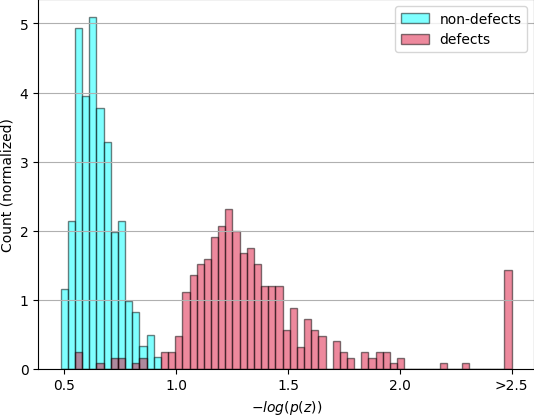

**ROC curve, all defects**

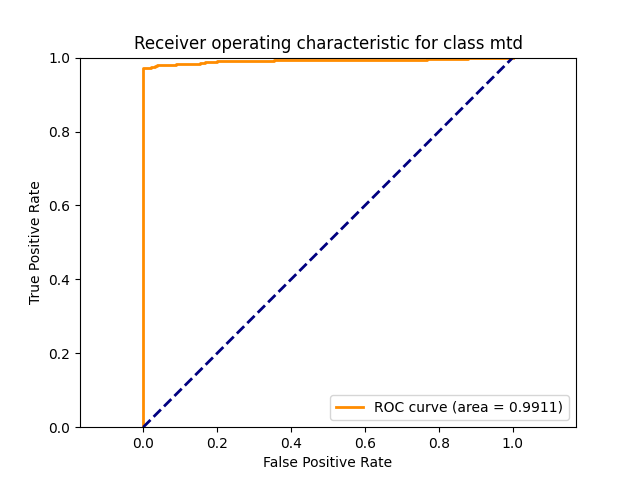

**ROC curve per defect type**

blowhole


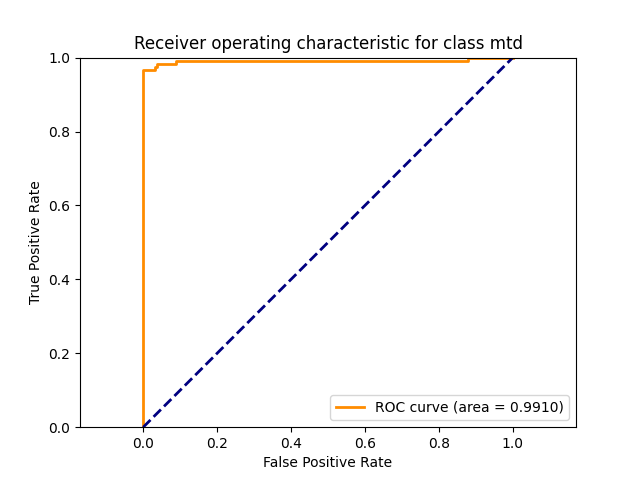

break


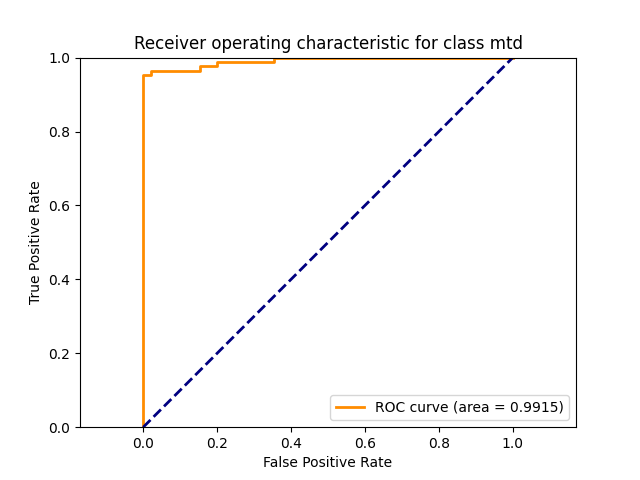

crack


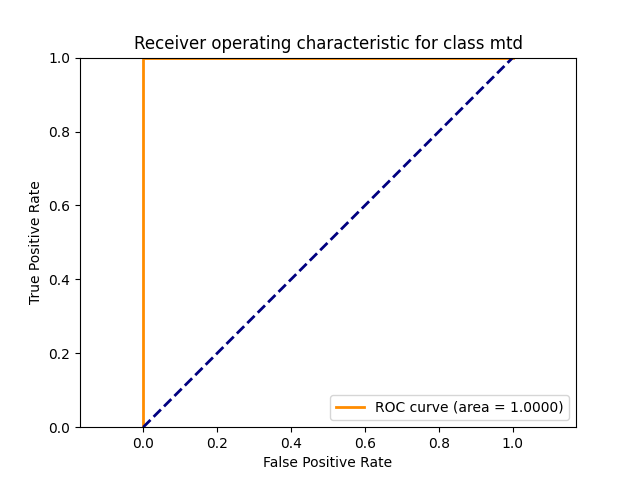

fray


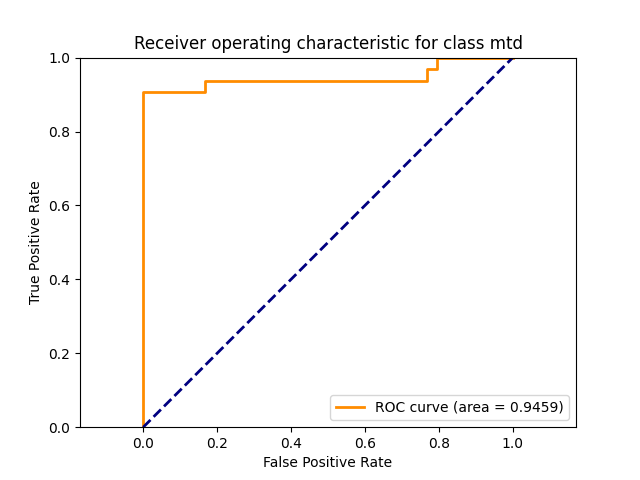

uneven


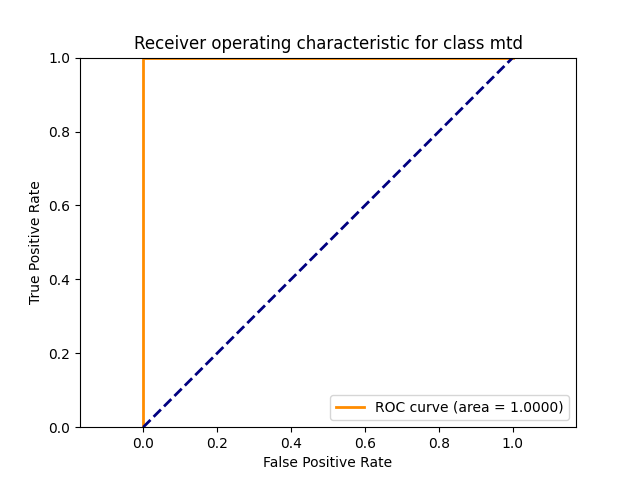

**Anomaly maps** (paper Fig. 7)

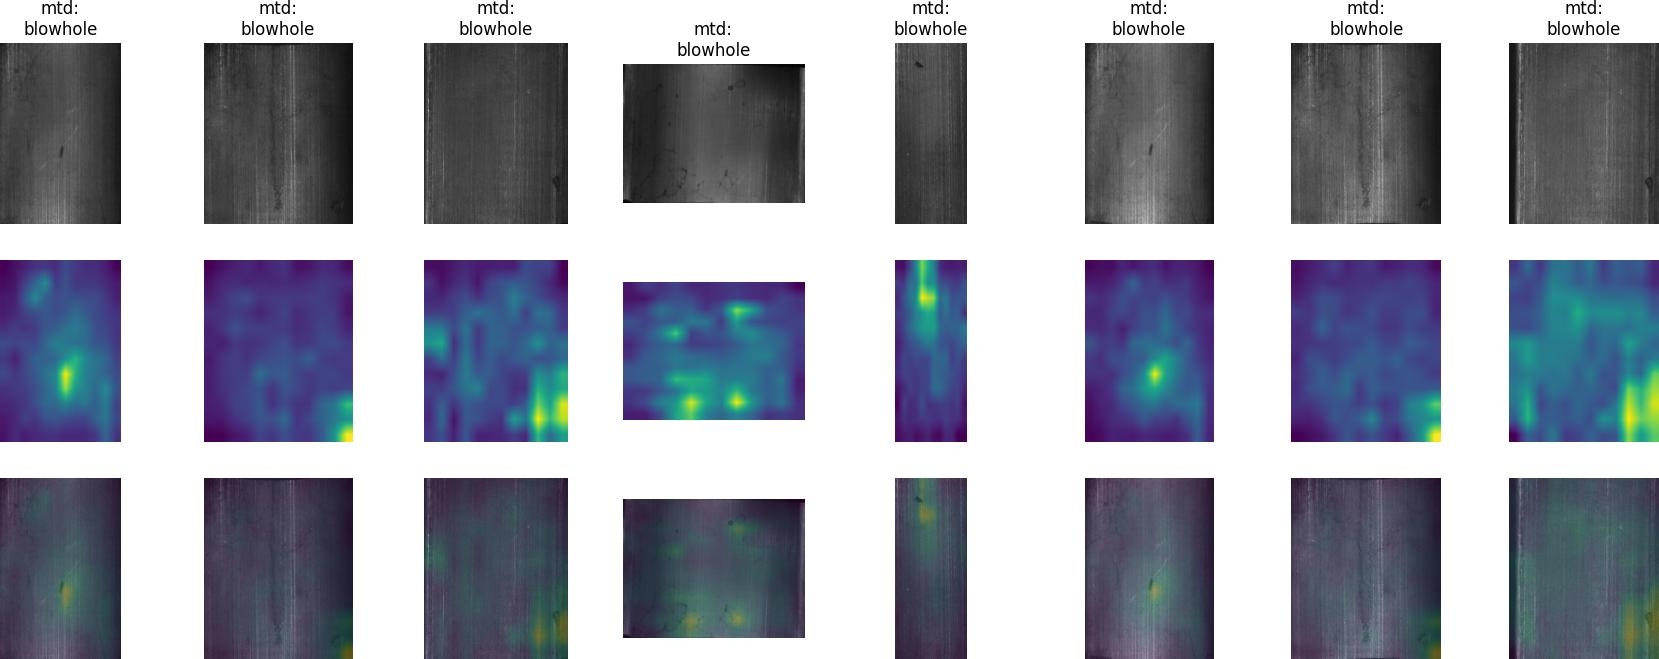

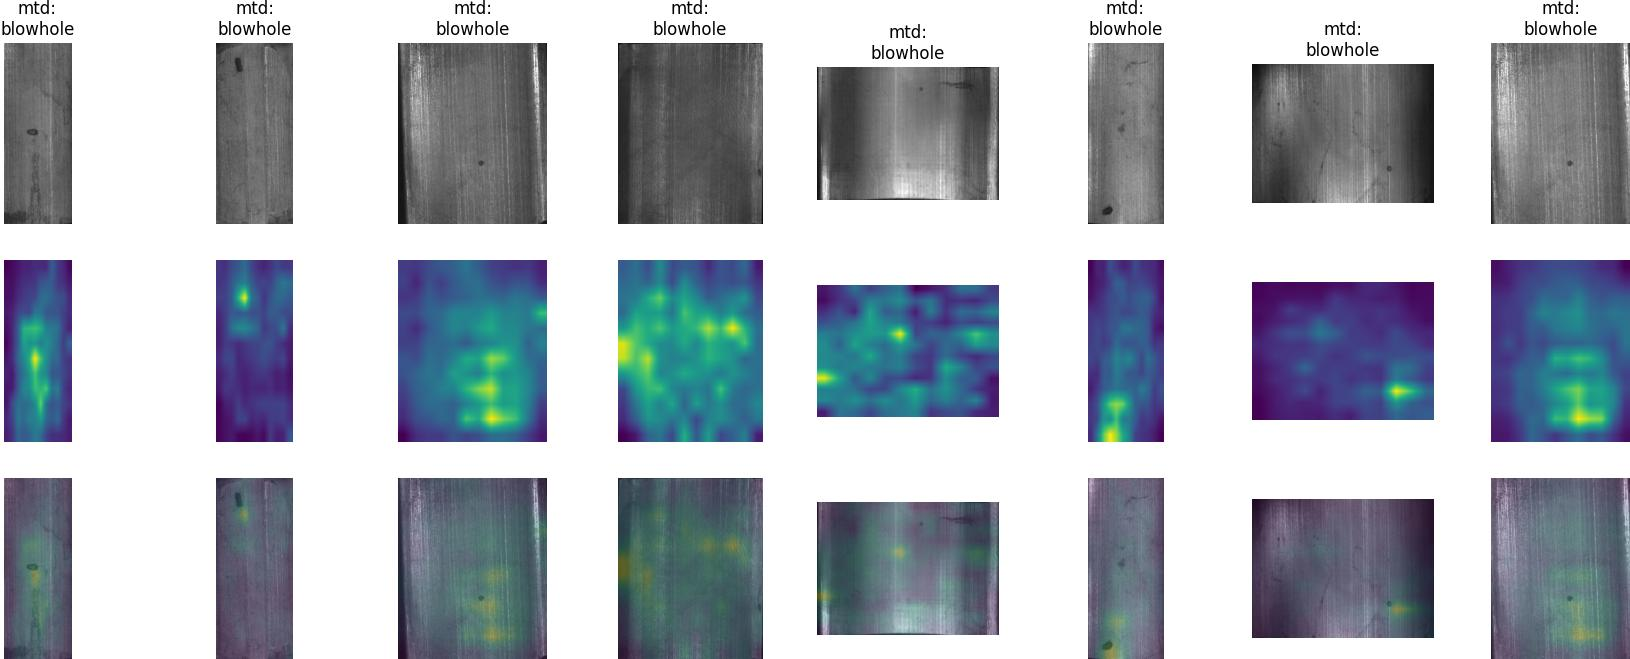

All figures: D:\learning 2\university\ENTC\5th sem\Image Processing and Machine Vision\Project\New Implementation\Notebook Implementation\viz\scores\mtd_seed0 and D:\learning 2\university\ENTC\5th sem\Image Processing and Machine Vision\Project\New Implementation\Notebook Implementation\viz\maps\mtd_seed0


In [20]:
# 7.2  Show the figures saved by evaluate

score_dir = PROJECT_DIR / 'viz' / 'scores' / c.modelname
map_dir = PROJECT_DIR / 'viz' / 'maps' / c.modelname

display(Markdown('**Anomaly-score histogram** (paper Fig. 5)'))
display(Image(filename=str(score_dir / 'score_histogram.png'), width=500))

display(Markdown('**ROC curve, all defects**'))
display(Image(filename=str(score_dir / 'all.png'), width=450))

display(Markdown('**ROC curve per defect type**'))
for png in sorted(score_dir.glob('*.png')):
    if png.name not in ('all.png', 'score_histogram.png'):
        print(png.stem)
        display(Image(filename=str(png), width=350))

display(Markdown('**Anomaly maps** (paper Fig. 7)'))
for jpg in sorted(map_dir.glob('*.jpg'), key=lambda p: int(p.stem) if p.stem.isdigit() else 0)[:2]:
    display(Image(filename=str(jpg), width=1000))
print(f'All figures: {score_dir} and {map_dir}')

---
## 8. more split seeds and the results table

One split is one sample. Two more seeds give a **mean ± std** to compare with the paper's 99.3.

In [21]:
# 8.1  Train and evaluate further seeds
EXTRA_SEEDS = [1, 2]

for seed in EXTRA_SEEDS:
    print(f'\n========================  SEED {seed}  ========================')
    prepare_mtd(seed=seed, class_name='mtd')
    set_config(dataset_path=DATASET_PATH, class_name='mtd', modelname=f'mtd_seed{seed}',
               img_size=(384, 384), meta_epochs=4, sub_epochs=15)
    run_feature_extraction()
    _, last_auroc, _ = run_training()
    save_result(seed, 'train_final_auroc', last_auroc)
    save_result(seed, 'eval_auroc', run_evaluation())
    print(f'RESULT seed {seed}: final AUROC = {last_auroc * 100:.2f} %   (paper: 99.3 %)')


========================  SEED 1  ========================
Split "mtd" (seed 1): train 762 | test 582 (good 190, defects 392)
config: dataset_path='data/mtd_data', class_name='mtd', modelname='mtd_seed1', img_size=(384, 384), meta_epochs=4, sub_epochs=15
Loaded pretrained weights for efficientnet-b5


100%|██████████| 37/37 [00:15<00:00,  2.38it/s]


Features saved to data/features/mtd/

Train epoch 0
Epoch: 0.0 	 train loss: 10.7497
Epoch: 0.4 	 train loss: 1.7579
Epoch: 0.8 	 train loss: 1.6199
Epoch: 0.12 	 train loss: 1.5349

Compute loss and scores on test set:
Epoch: 0 	 test_loss: 1.6137
AUROC: 	 last: 0.8594 	 max: 0.8594 	 epoch_max: 0 	 epoch_loss: 0

Train epoch 1

Compute loss and scores on test set:
Epoch: 1 	 test_loss: 1.2684
AUROC: 	 last: 0.9877 	 max: 0.9877 	 epoch_max: 1 	 epoch_loss: 0

Train epoch 2

Compute loss and scores on test set:
Epoch: 2 	 test_loss: 1.2376
AUROC: 	 last: 0.9944 	 max: 0.9944 	 epoch_max: 2 	 epoch_loss: 0

Train epoch 3

Compute loss and scores on test set:
Epoch: 3 	 test_loss: 1.3999
AUROC: 	 last: 0.9926 	 max: 0.9944 	 epoch_max: 2 	 epoch_loss: 0

Compute maps, loss and scores on test set:
AUC: 0.9926020408163265
RESULT seed 1: final AUROC = 99.26 %   (paper: 99.3 %)

========================  SEED 2  ========================
Split "mtd" (seed 2): train 762 | test 582 (good 190, 

100%|██████████| 37/37 [00:16<00:00,  2.28it/s]


Features saved to data/features/mtd/

Train epoch 0
Epoch: 0.0 	 train loss: 10.7492
Epoch: 0.4 	 train loss: 1.7241
Epoch: 0.8 	 train loss: 1.6075
Epoch: 0.12 	 train loss: 1.5319

Compute loss and scores on test set:
Epoch: 0 	 test_loss: 1.5585
AUROC: 	 last: 0.8934 	 max: 0.8934 	 epoch_max: 0 	 epoch_loss: 0

Train epoch 1

Compute loss and scores on test set:
Epoch: 1 	 test_loss: 1.2578
AUROC: 	 last: 0.9837 	 max: 0.9837 	 epoch_max: 1 	 epoch_loss: 0

Train epoch 2

Compute loss and scores on test set:
Epoch: 2 	 test_loss: 1.2548
AUROC: 	 last: 0.9869 	 max: 0.9869 	 epoch_max: 2 	 epoch_loss: 0

Train epoch 3

Compute loss and scores on test set:
Epoch: 3 	 test_loss: 1.4159
AUROC: 	 last: 0.9879 	 max: 0.9879 	 epoch_max: 3 	 epoch_loss: 0

Compute maps, loss and scores on test set:
AUC: 0.9879162191192266
RESULT seed 2: final AUROC = 98.79 %   (paper: 99.3 %)


In [22]:
# 8.2  Results table vs. the paper
results = json.loads(RESULTS_FILE.read_text())
print(f'{"split seed":>10} | {"AUROC (training)":>16} | {"AUROC (evaluate)":>16}')
print('-' * 50)
finals = []
for seed in sorted(results, key=int):
    tr, ev = results[seed].get('train_final_auroc'), results[seed].get('eval_auroc')
    if tr is not None:
        finals.append(tr * 100)
    fmt = lambda v: f'{v * 100:16.2f}' if v is not None else f'{"-":>16}'
    print(f'{seed:>10} | {fmt(tr)} | {fmt(ev)}')
print('-' * 50)
print(f'{"mean":>10} | {np.mean(finals):16.2f} | std {np.std(finals):.2f} over {len(finals)} seed(s)')
print(f'{"paper":>10} | {99.3:16.2f} |')

split seed | AUROC (training) | AUROC (evaluate)
--------------------------------------------------
         0 |            99.11 |            99.11
         1 |            99.26 |            99.26
         2 |            98.79 |            98.79
--------------------------------------------------
      mean |            99.05 | std 0.20 over 3 seed(s)
     paper |            99.30 |


In [24]:
# Threshold 

prepare_mtd(seed=0, class_name='mtd')    # rebuild the exact seed-0 split
import sys
!"{sys.executable}" csflow_inference.py --weights models/tmp/mtd_seed0 --calibrate data/mtd_data/mtd/test/good --out threshold.json

Split "mtd" (seed 0): train 762 | test 582 (good 190, defects 392)
Loaded pretrained weights for efficientnet-b5
Calibrated on 190 good images: threshold = 0.8897  -> threshold.json
good scores: min 0.4837  median 0.6377  max 0.9195
